# Section 4b — Network figures without Gephi

Generates the three network visualisations in matplotlib:

1. **Full network** coloured by Louvain community
2. **High-degree core** subgraph, labelled
3. **Sensors highlighted** on the network

**Why this is not a downgrade.** A seeded script is reproducible; GUI clicks are not. You can
legitimately write *"network visualisations were produced programmatically with NetworkX and
matplotlib using a fixed random seed"* - which is a stronger methodology statement than
describing a sequence of Gephi menu operations.

Runtime ~40s. Gephi becomes optional.

In [1]:
import pandas as pd, numpy as np, networkx as nx, json, time, random
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"savefig.dpi":300,"font.size":10})
SEED=42; random.seed(SEED); np.random.seed(SEED)

edges=pd.read_csv("data/gephi_edges.csv")
G=nx.DiGraph()
for r in edges.itertuples(index=False):
    G.add_edge(r.Source,r.Target,weight=int(r.Weight))
U=G.to_undirected()
deg=dict(G.degree())

def crop(ax, pos, nodes=None, pad=0.04):
    # zoom axes to the actual data extent - removes dead white space
    pts=np.array([pos[n] for n in (nodes if nodes is not None else pos)])
    x0,y0=pts.min(0); x1,y1=pts.max(0)
    dx,dy=(x1-x0) or 1,(y1-y0) or 1
    ax.set_xlim(x0-pad*dx, x1+pad*dx); ax.set_ylim(y0-pad*dy, y1+pad*dy)
print(f"{G.number_of_nodes():,} nodes / {G.number_of_edges():,} edges")

# communities
try:
    m=pd.read_csv("data/gephi_node_metrics.csv")
    idc="Id" if "Id" in m.columns else m.columns[0]
    mc=[x for x in m.columns if "odularity" in x.lower().replace(" ","")][0]
    comm=dict(zip(m[idc],m[mc]))
    print(f"communities from metrics file: {len(set(comm.values()))}")
except Exception:
    print("computing Louvain locally...")
    cs=nx.community.louvain_communities(U,weight="weight",seed=SEED)
    comm={v:i for i,g in enumerate(cs) for v in g}
    print(f"communities: {len(set(comm.values()))}")

6,434 nodes / 259,122 edges
communities from metrics file: 8


## Figure 1 — Full network

Layout is the slow step (~20s). Edges are drawn at very low alpha: at 259,122 edges anything
darker becomes an unreadable black mass - the exact problem that made the Gephi PDF unusable.

layout computed in 22.8s


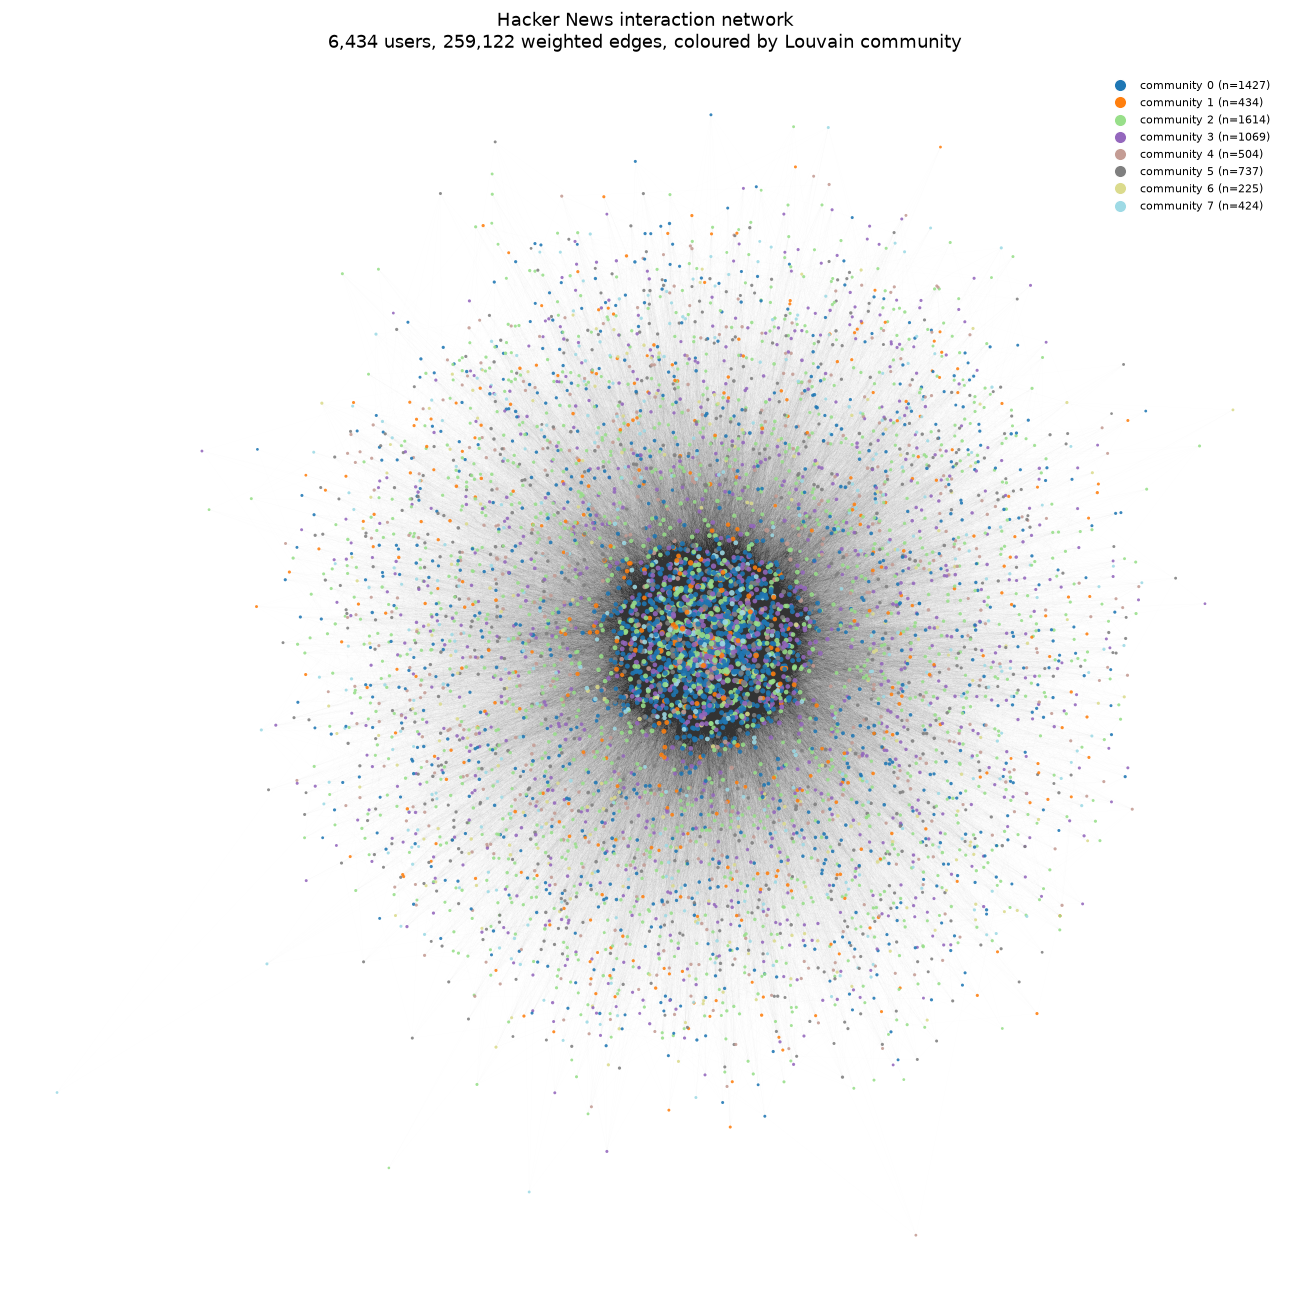

saved figures/fig_network_full.png


In [2]:
t=time.time()
pos=nx.spring_layout(U, k=0.08, iterations=25, seed=SEED)
print(f"layout computed in {time.time()-t:.1f}s")

order=sorted(set(comm.values()))
cmap=plt.cm.tab20(np.linspace(0,1,max(len(order),2)))
cidx={c_:i for i,c_ in enumerate(order)}
node_col=[cmap[cidx.get(comm.get(n,0),0)] for n in U.nodes()]
node_sz=[2+38*(deg[n]/max(deg.values()))**0.5 for n in U.nodes()]

fig,ax=plt.subplots(figsize=(13,13))
nx.draw_networkx_edges(U,pos,ax=ax,alpha=0.012,width=0.25,edge_color="#333333")
nx.draw_networkx_nodes(U,pos,ax=ax,node_color=node_col,node_size=node_sz,
                       linewidths=0,alpha=0.88)
ax.set_title(f"Hacker News interaction network\n{G.number_of_nodes():,} users, "
             f"{G.number_of_edges():,} weighted edges, coloured by Louvain community",
             fontsize=13,pad=16)
ax.axis("off")
sizes=pd.Series(comm).value_counts()
handles=[Line2D([0],[0],marker="o",color="w",markerfacecolor=cmap[cidx[c_]],markersize=9,
                label=f"community {c_} (n={sizes.get(c_,0)})") for c_ in order[:8]]
ax.legend(handles=handles,loc="upper right",frameon=False,fontsize=8)
crop(ax,pos)
plt.tight_layout(); plt.savefig("figures/fig_network_full.png",bbox_inches="tight",facecolor="white")
plt.show(); print("saved figures/fig_network_full.png")

## Figure 2 — High-degree core

The full view shows scale but hides structure. Filtering to high-degree users makes the core
readable. Threshold chosen so roughly 250-350 nodes survive.

degree>=300: 304 nodes / 11,188 edges


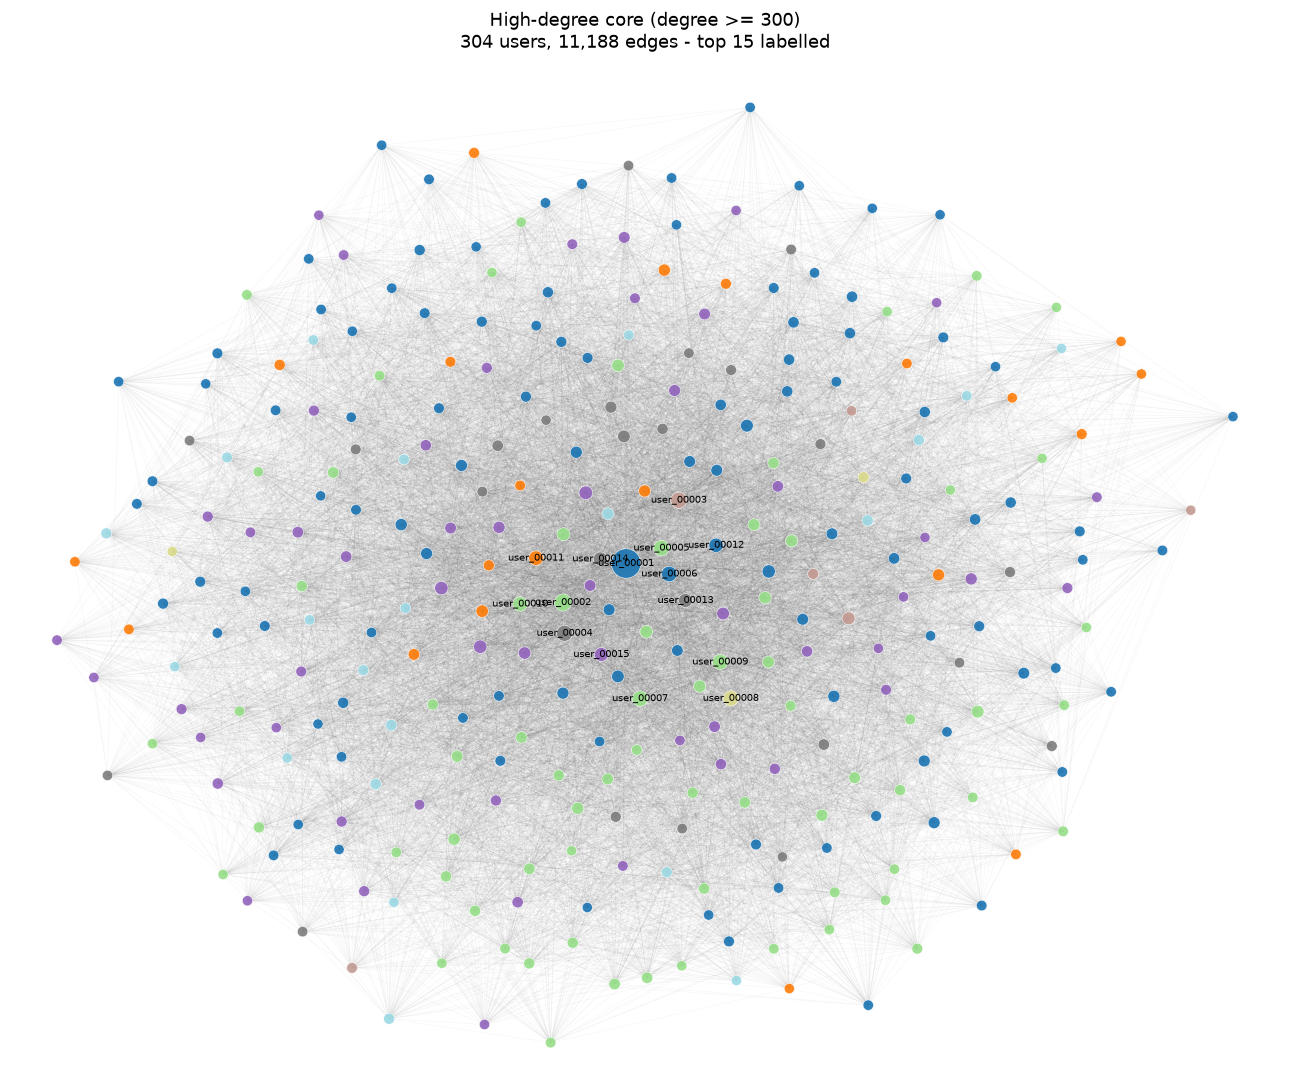

saved figures/fig_network_core.png


In [3]:
THRESH=300
keep=[n for n in G if deg[n]>=THRESH]
sub=U.subgraph(keep).copy()
print(f"degree>={THRESH}: {sub.number_of_nodes():,} nodes / {sub.number_of_edges():,} edges")

pos_c=nx.spring_layout(sub,k=0.5,iterations=60,seed=SEED)
col_c=[cmap[cidx.get(comm.get(n,0),0)] for n in sub.nodes()]
sz_c=[30+420*(deg[n]/max(deg[x] for x in sub))**1.4 for n in sub.nodes()]

fig,ax=plt.subplots(figsize=(13,11))
nx.draw_networkx_edges(sub,pos_c,ax=ax,alpha=0.05,width=0.4,edge_color="#444444")
nx.draw_networkx_nodes(sub,pos_c,ax=ax,node_color=col_c,node_size=sz_c,
                       linewidths=0.4,edgecolors="white",alpha=0.92)
top=sorted(sub.nodes(),key=lambda n:-deg[n])[:15]
try:
    lab=pd.read_csv("data/gephi_nodes.csv"); L=dict(zip(lab.Id,lab.Label))
except Exception:
    L={}
nx.draw_networkx_labels(sub,pos_c,ax=ax,font_size=7,
    labels={n:L.get(n,n[:8]) for n in top})
ax.set_title(f"High-degree core (degree >= {THRESH})\n{sub.number_of_nodes()} users, "
             f"{sub.number_of_edges():,} edges - top 15 labelled",fontsize=13,pad=16)
ax.axis("off"); crop(ax,pos_c)
plt.tight_layout(); plt.savefig("figures/fig_network_core.png",bbox_inches="tight",facecolor="white")
plt.show(); print("saved figures/fig_network_core.png")

## Figure 3 — Sensors highlighted

The key visual: the network with the CELF-selected monitoring sensors marked. Shows data,
method and result in one frame.

20 sensors mapped to graph ids
30 influence seeds loaded


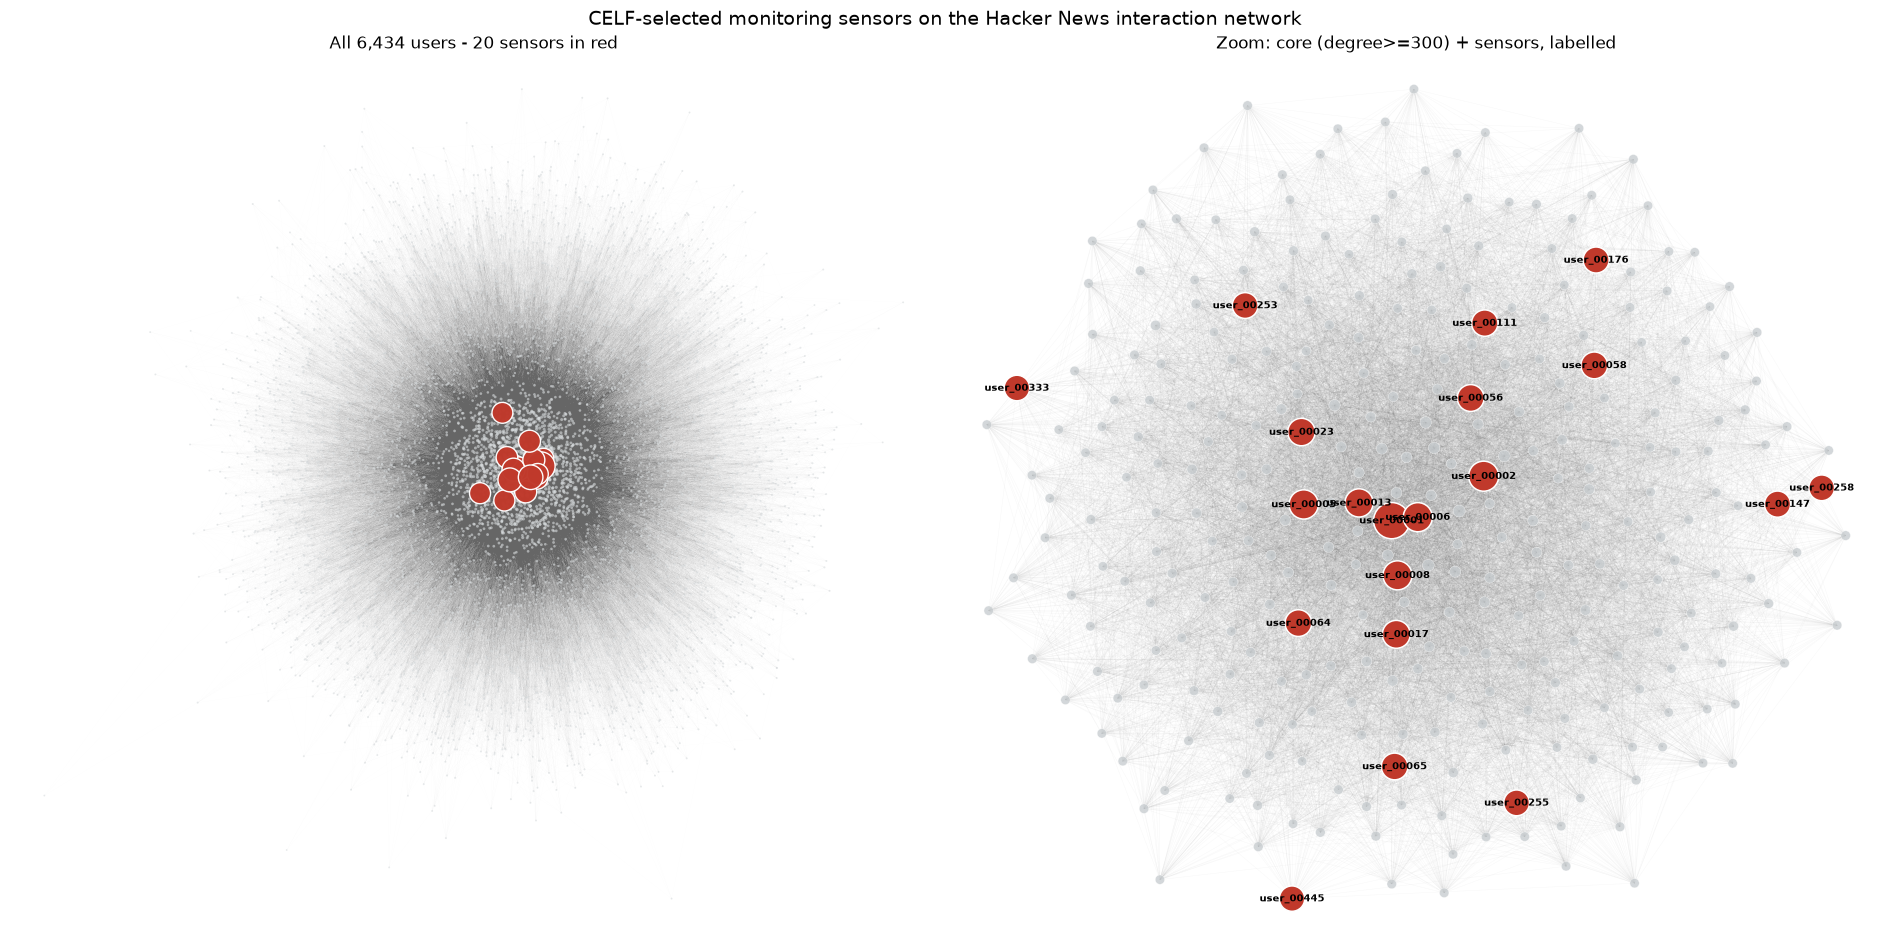

saved figures/fig_network_sensors.png


In [4]:
h2u=json.load(open("username_mapping_v3_PRIVATE.json"))
u2h={v:k for k,v in h2u.items()}
sensors_u=[r for r in pd.read_csv("data/sensors.csv")["sensor"]]
sensors_h=[u2h[u] for u in sensors_u if u in u2h]
print(f"{len(sensors_h)} sensors mapped to graph ids")

try:
    seeds_h=[r["Id"] for _,r in pd.read_csv("celf_seeds.csv").iterrows() if r["is_seed"]=="SEED"]
except Exception:
    seeds_h=[]
print(f"{len(seeds_h)} influence seeds loaded")

S=set(sensors_h)

fig,axes=plt.subplots(1,2,figsize=(19,9.6))

# --- left: sensors on the whole network (no labels - they would pile up) ---
axL=axes[0]
nx.draw_networkx_edges(U,pos,ax=axL,alpha=0.010,width=0.22,edge_color="#666666")
others=[n for n in U.nodes() if n not in S]
nx.draw_networkx_nodes(U,pos,ax=axL,nodelist=others,node_color="#d8dcde",
                       node_size=[1.2+11*(deg[n]/max(deg.values()))**0.5 for n in others],
                       linewidths=0,alpha=0.6)
nx.draw_networkx_nodes(U,pos,ax=axL,nodelist=list(S),node_color="#c0392b",
                       node_size=[120+300*(deg[n]/max(deg.values()))**0.5 for n in S],
                       linewidths=1.0,edgecolors="white",alpha=0.98)
axL.set_title(f"All {G.number_of_nodes():,} users - {len(S)} sensors in red",fontsize=12)
axL.axis("off"); crop(axL,pos)

# --- right: zoom to the core, where sensors are separable and labels fit ---
core_nodes=[n for n in G if deg[n]>=THRESH] if 'THRESH' in dir() else [n for n in G if deg[n]>=300]
zoom=sorted(set(core_nodes)|S)
sz=U.subgraph(zoom).copy()
pos_z=nx.spring_layout(sz,k=0.55,iterations=70,seed=SEED)
axR=axes[1]
nx.draw_networkx_edges(sz,pos_z,ax=axR,alpha=0.045,width=0.35,edge_color="#555555")
oth=[n for n in sz.nodes() if n not in S]
nx.draw_networkx_nodes(sz,pos_z,ax=axR,nodelist=oth,node_color="#c9ced1",
                       node_size=[22+120*(deg[n]/max(deg.values()))**0.8 for n in oth],
                       linewidths=0.3,edgecolors="white",alpha=0.8)
nx.draw_networkx_nodes(sz,pos_z,ax=axR,nodelist=[n for n in S if n in sz],node_color="#c0392b",
                       node_size=[260+420*(deg[n]/max(deg.values()))**0.8 for n in S if n in sz],
                       linewidths=1.1,edgecolors="white")
try:
    lab=pd.read_csv("data/gephi_nodes.csv"); L=dict(zip(lab.Id,lab.Label))
except Exception:
    L={}
nx.draw_networkx_labels(sz,pos_z,ax=axR,font_size=7.5,font_weight="bold",
    labels={n:L.get(n,n[:8]) for n in S if n in sz})
axR.set_title(f"Zoom: core (degree>={THRESH}) + sensors, labelled",fontsize=12)
axR.axis("off"); crop(axR,pos_z)

fig.suptitle("CELF-selected monitoring sensors on the Hacker News interaction network",
             fontsize=14,y=0.975)
plt.tight_layout()
plt.savefig("figures/fig_network_sensors.png",bbox_inches="tight",facecolor="white")
plt.show(); print("saved figures/fig_network_sensors.png")

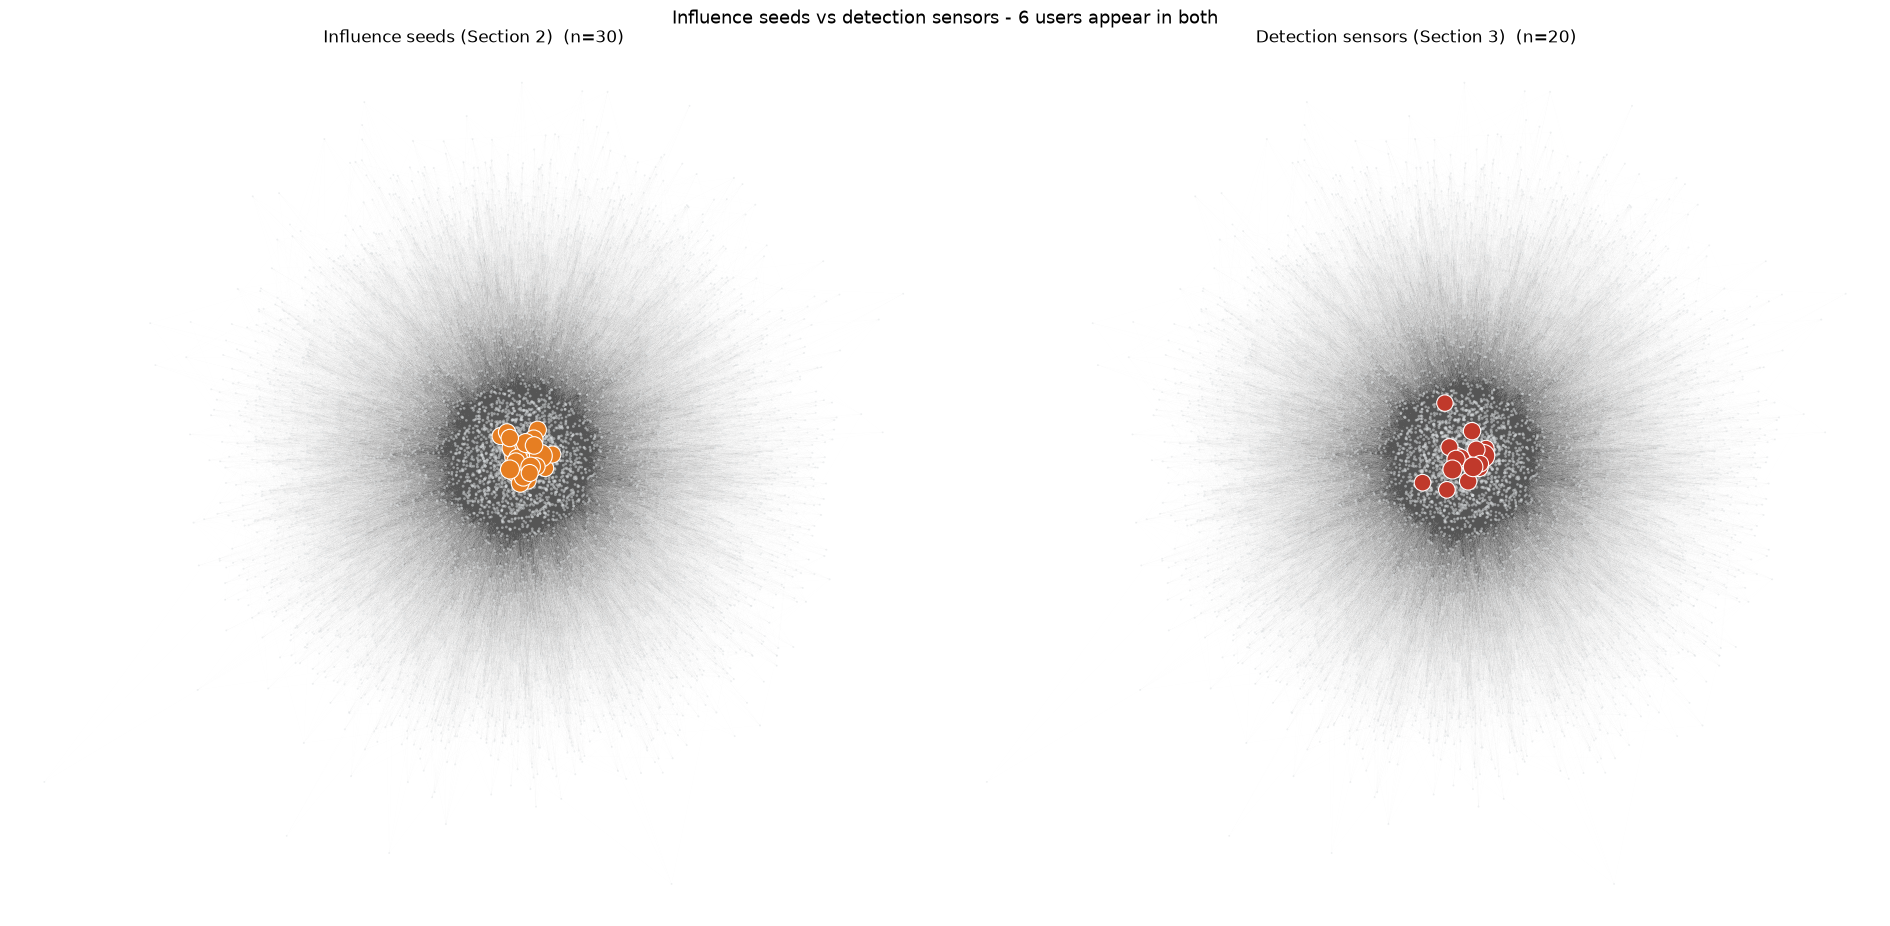

saved figures/fig_network_seeds_vs_sensors.png  |  overlap = 6 users
A small overlap is a finding: the best broadcasters are not the best listeners.


In [5]:
# side-by-side: influence seeds vs detection sensors
if seeds_h:
    fig,axes=plt.subplots(1,2,figsize=(19,9.5))
    for axx,(grp,ttl,col) in zip(axes,[(set(seeds_h),"Influence seeds (Section 2)","#e67e22"),
                                       (S,"Detection sensors (Section 3)","#c0392b")]):
        nx.draw_networkx_edges(U,pos,ax=axx,alpha=0.008,width=0.22,edge_color="#555555")
        oth=[n for n in U.nodes() if n not in grp]
        nx.draw_networkx_nodes(U,pos,ax=axx,nodelist=oth,node_color="#dde1e3",
                               node_size=[1.2+10*(deg[n]/max(deg.values()))**0.5 for n in oth],
                               linewidths=0,alpha=0.5)
        nx.draw_networkx_nodes(U,pos,ax=axx,nodelist=list(grp),node_color=col,
                               node_size=[70+200*(deg[n]/max(deg.values()))**0.5 for n in grp],
                               linewidths=0.8,edgecolors="white")
        overlap=len(grp & S) if grp is not S else len(S)
        axx.set_title(f"{ttl}  (n={len(grp)})",fontsize=12); axx.axis("off"); crop(axx,pos)
    ov=len(set(seeds_h)&S)
    fig.suptitle(f"Influence seeds vs detection sensors - {ov} users appear in both",
                 fontsize=13,y=0.97)
    plt.tight_layout(); plt.savefig("figures/fig_network_seeds_vs_sensors.png",
                                    bbox_inches="tight",facecolor="white")
    plt.show()
    print(f"saved figures/fig_network_seeds_vs_sensors.png  |  overlap = {ov} users")
    print("A small overlap is a finding: the best broadcasters are not the best listeners.")

## Done

| File | Use |
|---|---|
| `figures/fig_network_full.png` | Full network, community-coloured |
| `figures/fig_network_core.png` | High-degree core, labelled |
| `figures/fig_network_sensors.png` | **Sensors highlighted - the key visual** |
| `figures/fig_network_seeds_vs_sensors.png` | Influence seeds vs detection sensors |

**Methodology sentence:**

> *"Network visualisations were produced programmatically using NetworkX and matplotlib with a
> fixed random seed (Fruchterman-Reingold force-directed layout), ensuring the figures are exactly
> reproducible from the analysis code."*

Gephi is no longer required. If you still want it for an additional view, fine - but nothing
in your report now depends on it.